# 04 · Regression Assumptions and Model Diagnostics

**Syllabus:** Unit 2 (residual analysis, multicollinearity/VIF, heteroscedasticity, autocorrelation/Durbin-Watson and remedies) and Unit 3 (added-variable plots, studentized deleted residuals, leverage, DFFITS, Cook's distance, DFBETAS).

**Report item:** *Regression Assumption Testing*.

Model checked: **MLR 2** from notebook 03 (8 pollutants + season), fitted on the training period.

## 1. Setup (same data and split as notebook 03)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, linear_rainbow, acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
%matplotlib inline

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
FIG = ROOT / "reports" / "figures"
TAB = ROOT / "reports" / "tables"
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)

PREDICTORS = ["PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3"]
df = pd.read_csv(ROOT / "data" / "processed" / "bengaluru_clean.csv", parse_dates=["Date"]).rename(columns={"PM2.5": "PM25"})
model_df = df.dropna(subset=["PM25"] + PREDICTORS).reset_index(drop=True)
SPLIT_DATE = pd.Timestamp(pd.read_csv(TAB / "train_test_split.csv")["SPLIT_DATE"][0])
train = model_df[model_df["Date"] < SPLIT_DATE].reset_index(drop=True)
test = model_df[model_df["Date"] >= SPLIT_DATE].reset_index(drop=True)

RHS = " + ".join(PREDICTORS) + " + C(Season, Treatment('Winter'))"
ols = smf.ols("PM25 ~ " + RHS, data=train).fit()
print(f"Train rows: {len(train)} | Adj R2 = {ols.rsquared_adj:.3f}")

Train rows: 1181 | Adj R2 = 0.563


## 2. A helper that runs every assumption test

The same function is used before and after the remedies, so the results can be compared side by side.

In [2]:
def assumption_tests(res, name):
    r = res.resid
    jb_stat, jb_p, skew, kurt = jarque_bera(r)
    sw_p = stats.shapiro(r)[1]
    bp_p = het_breuschpagan(r, res.model.exog)[1]
    white_p = het_white(r, res.model.exog)[1]
    rb_p = linear_rainbow(res)[1]
    lb_p = acorr_ljungbox(r, lags=[7], return_df=True)["lb_pvalue"].iloc[0]
    return pd.Series({
        "Linearity: Rainbow p": rb_p,
        "Normality: residual skew": skew,
        "Normality: Jarque-Bera p": jb_p,
        "Normality: Shapiro-Wilk p": sw_p,
        "Homoscedasticity: Breusch-Pagan p": bp_p,
        "Homoscedasticity: White p": white_p,
        "Independence: Durbin-Watson": durbin_watson(r),
        "Independence: Ljung-Box (lag 7) p": lb_p,
    }, name=name)

before = assumption_tests(ols, "MLR 2 (PM2.5)")
before.to_frame()

/usr/local/lib/python3.13/site-packages/statsmodels/stats/diagnostic.py:1272: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  resols = OLS(y**2, exog).fit()


,MLR 2 (PM2.5)
Linearity: Rainbow p,0.0003
Normality: residual skew,2.5915
Normality: Jarque-Bera p,0.0000
Normality: Shapiro-Wilk p,0.0000
Homoscedasticity: Breusch-Pagan p,0.0000
Homoscedasticity: White p,0.0000
Independence: Durbin-Watson,0.9991
Independence: Ljung-Box (lag 7) p,0.0000


**Reading the table:** for each test, H₀ is that the assumption holds. A p-value below 0.05 means the assumption is violated. Durbin-Watson ranges 0-4; about 2 means no autocorrelation, below 1.5 means positive autocorrelation.

## 3. Residual plots (graphical checks)

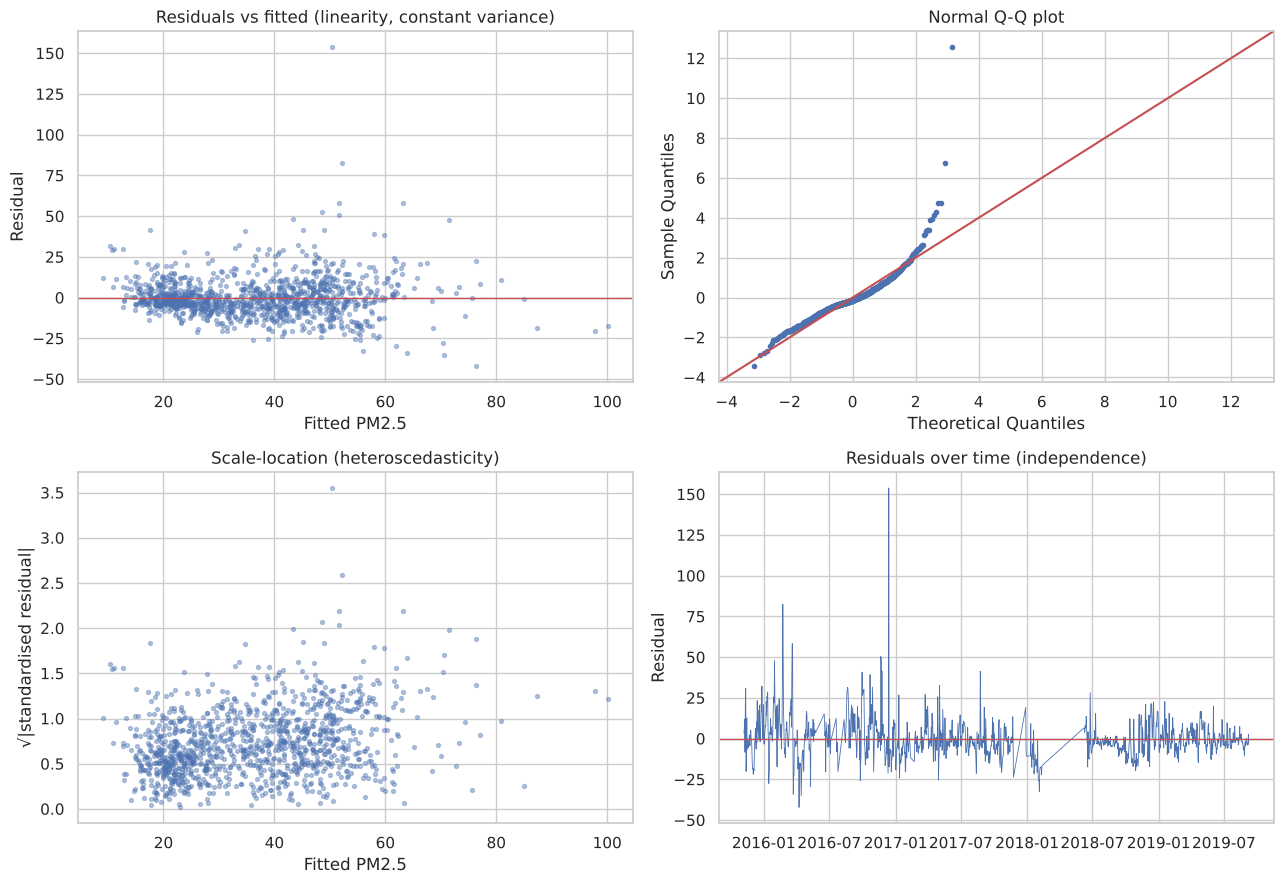

In [3]:
fitted, resid = ols.fittedvalues, ols.resid
std_resid = ols.get_influence().resid_studentized_internal

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0, 0].scatter(fitted, resid, s=8, alpha=0.4); axes[0, 0].axhline(0, color="r", lw=1)
axes[0, 0].set(title="Residuals vs fitted (linearity, constant variance)", xlabel="Fitted PM2.5", ylabel="Residual")
sm.qqplot(resid, line="45", fit=True, ax=axes[0, 1], markersize=3); axes[0, 1].set_title("Normal Q-Q plot")
axes[1, 0].scatter(fitted, np.sqrt(np.abs(std_resid)), s=8, alpha=0.4)
axes[1, 0].set(title="Scale-location (heteroscedasticity)", xlabel="Fitted PM2.5", ylabel="√|standardised residual|")
axes[1, 1].plot(train["Date"], resid, lw=0.6); axes[1, 1].axhline(0, color="r", lw=1)
axes[1, 1].set(title="Residuals over time (independence)", ylabel="Residual")
fig.tight_layout(); fig.savefig(FIG / "09_residual_diagnostics.png", dpi=150); plt.show()

**Observations:** the Q-Q plot bends sharply upward in the right tail (a few extreme spike days), the residual spread grows with the fitted value (funnel shape), and residuals drift in long runs over time (autocorrelation).

## 4. Multicollinearity: Variance Inflation Factor

$VIF_j = 1/(1-R_j^2)$, where $R_j^2$ comes from regressing predictor $j$ on all the other predictors. Rule of thumb: VIF > 5 is a concern and VIF > 10 is serious.

In [4]:
X = sm.add_constant(train[PREDICTORS])
vif = pd.DataFrame({
    "VIF": [variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
}, index=PREDICTORS)
vif["Tolerance (1/VIF)"] = 1 / vif["VIF"]
vif.to_csv(TAB / "vif.csv")
vif.sort_values("VIF", ascending=False)

,VIF,Tolerance (1/VIF)
NO,2.2162,0.4512
NO2,1.7888,0.5590
NOx,1.7120,0.5841
PM10,1.4053,0.7116
O3,1.3693,0.7303
SO2,1.3690,0.7305
NH3,1.1217,0.8915
CO,1.0315,0.9694


**Conclusion:** every VIF is below 2.5, so there is **no serious multicollinearity**. The sign changes in NO and NO2 between the models in notebook 03 came mainly from season acting as a confounder, not from collinearity. All 8 predictors are therefore kept. Ridge/LASSO in Phase 2 will still be compared.

## 5. Remedy 1: log transform of the target

The right-skewed target and the funnel-shaped residuals suggest the effects are **multiplicative**. Modelling $\log(PM2.5)$ usually fixes both, and every prediction becomes positive after back-transforming.

In [5]:
log_ols = smf.ols("np.log(PM25) ~ " + RHS, data=train).fit()
after = assumption_tests(log_ols, "MLR 2 (log PM2.5)")
compare = pd.concat([before, after], axis=1)
compare.loc["Adjusted R²"] = [ols.rsquared_adj, log_ols.rsquared_adj]
compare

/usr/local/lib/python3.13/site-packages/statsmodels/stats/diagnostic.py:1272: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  resols = OLS(y**2, exog).fit()


,MLR 2 (PM2.5),MLR 2 (log PM2.5)
Linearity: Rainbow p,0.0003,0.1045
Normality: residual skew,2.5915,-0.2013
Normality: Jarque-Bera p,0.0000,0.0000
Normality: Shapiro-Wilk p,0.0000,0.0000
Homoscedasticity: Breusch-Pagan p,0.0000,0.0000
Homoscedasticity: White p,0.0000,0.0000
Independence: Durbin-Watson,0.9991,0.9041
Independence: Ljung-Box (lag 7) p,0.0000,0.0000
Adjusted R²,0.5630,0.6091


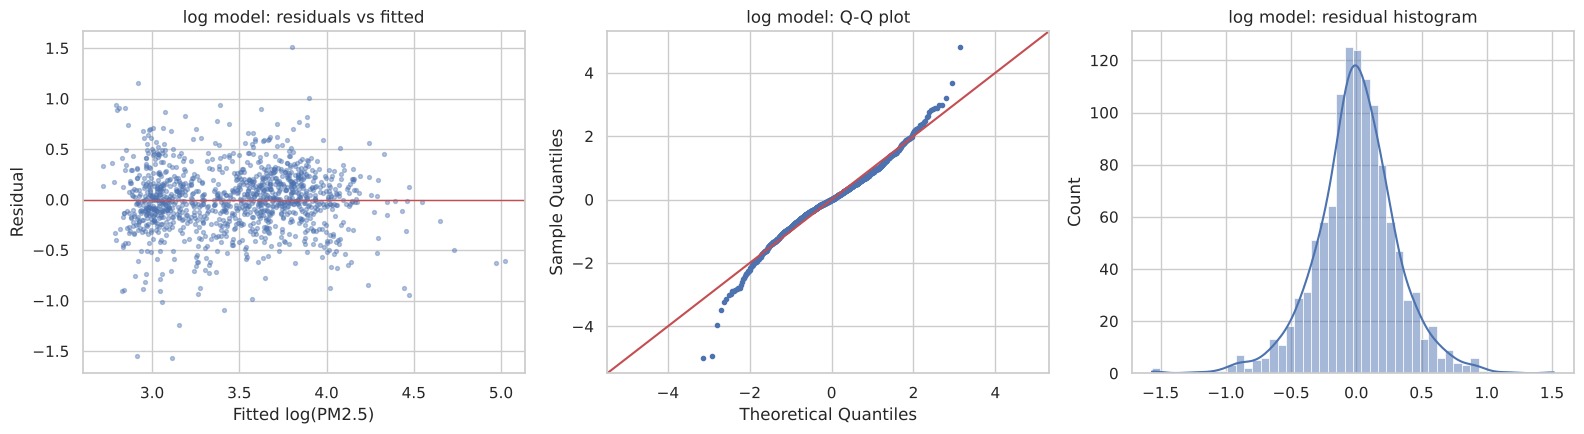

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(log_ols.fittedvalues, log_ols.resid, s=8, alpha=0.4); axes[0].axhline(0, color="r", lw=1)
axes[0].set(title="log model: residuals vs fitted", xlabel="Fitted log(PM2.5)", ylabel="Residual")
sm.qqplot(log_ols.resid, line="45", fit=True, ax=axes[1], markersize=3); axes[1].set_title("log model: Q-Q plot")
sns.histplot(log_ols.resid, kde=True, ax=axes[2]); axes[2].set_title("log model: residual histogram")
fig.tight_layout(); fig.savefig(FIG / "10_log_model_residuals.png", dpi=150); plt.show()

## 6. Remedy 2: robust standard errors for heteroscedasticity

Unequal variance does not bias the coefficients, but it makes the ordinary standard errors (and so the p-values) wrong. **White / HC3** standard errors stay valid under heteroscedasticity.

## 7. Autocorrelation: Durbin-Watson test and remedy

$d = \frac{\sum_{t=2}^{n}(e_t-e_{t-1})^2}{\sum e_t^2} \approx 2(1-\hat\rho)$

With n ≈ 1180 and k = 11 predictors, the 5% critical values are about $d_L \approx 1.86$ and $d_U \approx 1.92$. A value below $d_L$ means positive autocorrelation.

Durbin-Watson d = 0.904  ->  estimated rho = 0.548


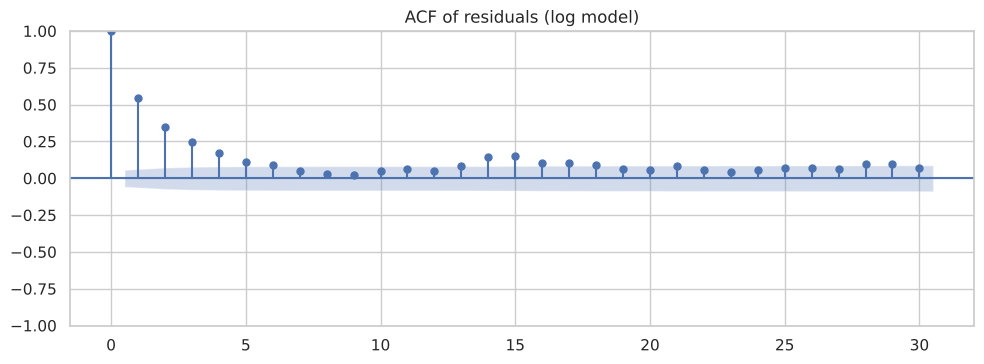

In [7]:
d = durbin_watson(log_ols.resid)
rho = 1 - d / 2
print(f"Durbin-Watson d = {d:.3f}  ->  estimated rho = {rho:.3f}")

fig, ax = plt.subplots(figsize=(10, 3.8))
plot_acf(log_ols.resid, lags=30, ax=ax)
ax.set_title("ACF of residuals (log model)")
fig.tight_layout(); fig.savefig(FIG / "11_residual_acf.png", dpi=150); plt.show()

**Remedies used:**
1. **Cochrane-Orcutt / feasible GLS with AR(1) errors** (`GLSAR`): estimates ρ and transforms the model to remove the correlation.
2. **Newey-West (HAC) standard errors:** keep the OLS coefficients but correct the standard errors for both autocorrelation and heteroscedasticity.

In [8]:
y_log, X_design = log_ols.model.endog, log_ols.model.exog
glsar = sm.GLSAR(y_log, X_design, rho=1).iterative_fit(maxiter=20)
gls_dw = durbin_watson(glsar.wresid)
print(f"Estimated AR(1) rho = {glsar.model.rho[0]:.3f}")
print(f"Durbin-Watson after Cochrane-Orcutt transform = {gls_dw:.3f}")

names = log_ols.params.index
hc3 = log_ols.get_robustcov_results(cov_type="HC3")
hac = log_ols.get_robustcov_results(cov_type="HAC", maxlags=7)
se_table = pd.DataFrame({
    "coef (OLS)": log_ols.params.values,
    "SE OLS": log_ols.bse.values,
    "SE HC3": hc3.bse,
    "SE HAC (Newey-West)": hac.bse,
    "p OLS": log_ols.pvalues.values,
    "p HAC": hac.pvalues,
    "coef (GLSAR)": glsar.params,
    "p GLSAR": glsar.pvalues,
}, index=names)
se_table.to_csv(TAB / "robust_se_comparison.csv")
se_table.round(4)

Estimated AR(1) rho = 0.579
Durbin-Watson after Cochrane-Orcutt transform = 2.071


,coef (OLS),SE OLS,SE HC3,SE HAC (Newey-West),p OLS,p HAC,coef (GLSAR),p GLSAR
Intercept,2.7137,0.0604,0.0626,0.0977,0.0000,0.0000,2.9221,0.0000
"C(Season, Treatment('Winter'))[T.Monsoon]",-0.3629,0.0324,0.0357,0.0580,0.0000,0.0000,-0.4240,0.0000
"C(Season, Treatment('Winter'))[T.Post-monsoon]",-0.0422,0.0321,0.0328,0.0569,0.1888,0.4589,-0.1162,0.0350
"C(Season, Treatment('Winter'))[T.Summer]",-0.0306,0.0301,0.0276,0.0449,0.3100,0.4962,-0.0590,0.2531
PM10,0.0042,0.0003,0.0004,0.0005,0.0000,0.0000,0.0032,0.0000
NO,-0.0076,0.0018,0.0020,0.0024,0.0000,0.0015,-0.0073,0.0001
NO2,0.0047,0.0011,0.0012,0.0017,0.0000,0.0047,0.0026,0.0499
NOx,0.0080,0.0007,0.0008,0.0011,0.0000,0.0000,0.0079,0.0000
NH3,0.0043,0.0008,0.0010,0.0019,0.0000,0.0268,0.0037,0.0002
CO,-0.0283,0.0104,0.0128,0.0161,0.0068,0.0794,-0.0060,0.6516


**Observation:** the HAC standard errors are larger than the OLS ones, because autocorrelation makes OLS over-confident. Predictors that stay significant under HAC and GLSAR are the reliable ones.

# Model diagnostics: outliers and influential observations (Unit 3)

Run on the log model. $n$ = observations and $p$ = number of parameters. Thresholds used:

| Measure | What it detects | Flag if |
|---|---|---|
| Studentized deleted residual $t_i$ | Outlying **Y** | $|t_i| > t_{1-\alpha/2n,\,n-p-1}$ (Bonferroni) |
| Leverage $h_{ii}$ (hat matrix diagonal) | Outlying **X** | $h_{ii} > 2p/n$ |
| DFFITS | Influence on own fitted value | $|DFFITS| > 2\sqrt{p/n}$ |
| Cook's distance $D_i$ | Influence on all fitted values | $D_i > 4/n$ (or $> F_{0.5,p,n-p}$ = strong) |
| DFBETAS | Influence on each coefficient | $|DFBETAS| > 2/\sqrt n$ |

## 8. Added-variable (partial regression) plots

Each panel shows the relationship between log(PM2.5) and one predictor **after removing the effect of all the other predictors**. The slope of each panel equals that predictor's coefficient in the full model.

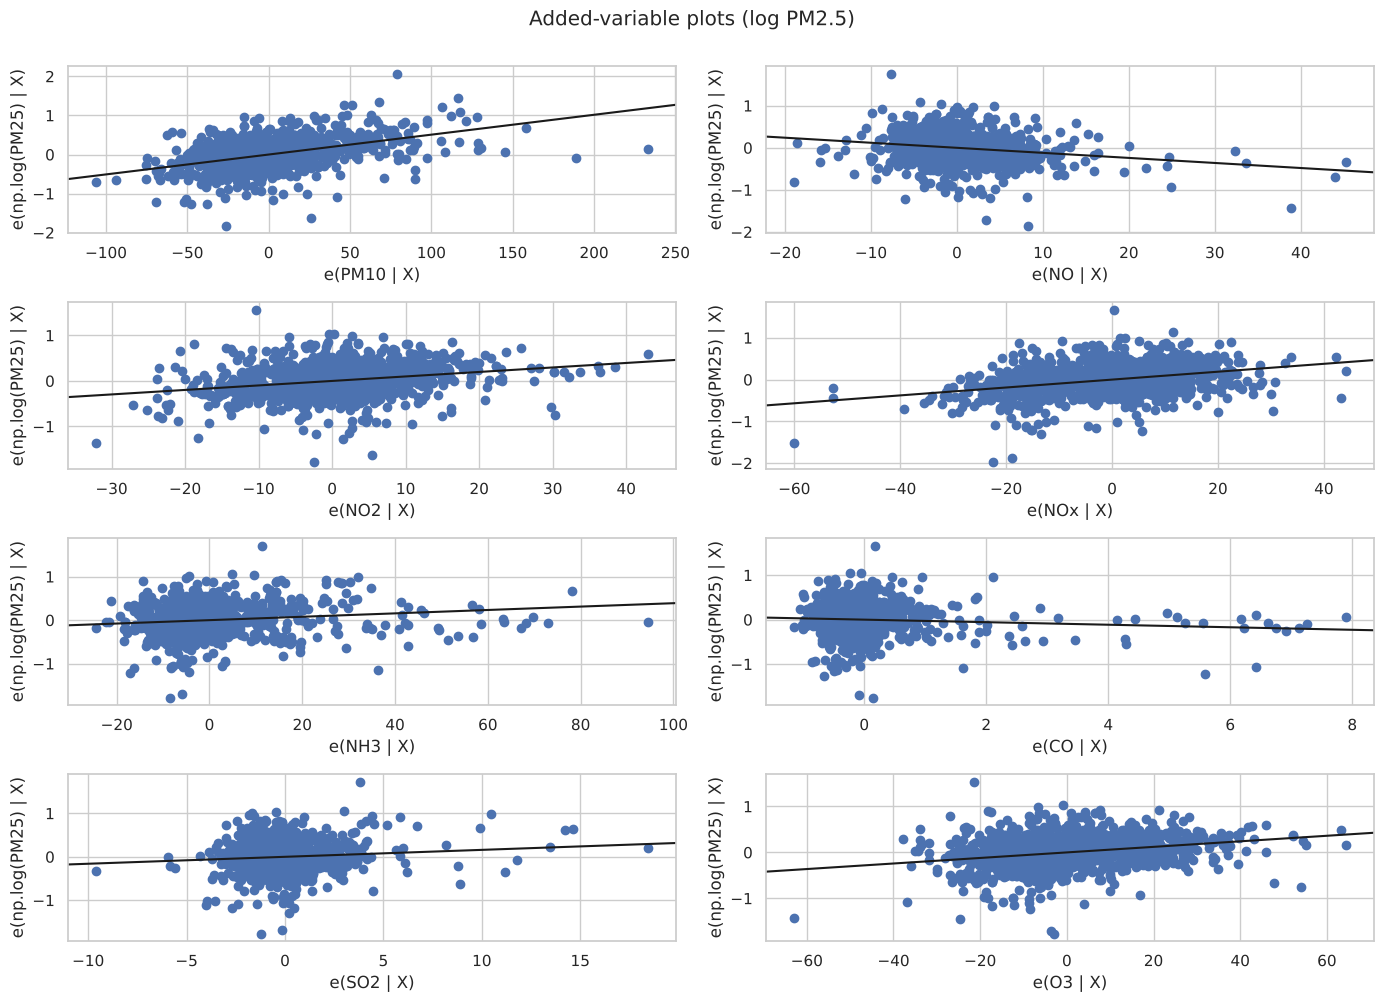

In [9]:
num_rhs = " + ".join(PREDICTORS)
fig = plt.figure(figsize=(14, 10))
sm.graphics.plot_partregress_grid(smf.ols("np.log(PM25) ~ " + num_rhs, data=train).fit(), exog_idx=PREDICTORS, fig=fig)
fig.suptitle("Added-variable plots (log PM2.5)", y=1.0)
fig.tight_layout(); fig.savefig(FIG / "12_added_variable_plots.png", dpi=150); plt.show()

## 9. Influence measures

In [10]:
infl = OLSInfluence(log_ols)
n, p = int(log_ols.nobs), int(log_ols.df_model) + 1

measures = pd.DataFrame({
    "Date": train["Date"].dt.date,
    "PM2.5": train["PM25"],
    "stud_deleted_resid": infl.resid_studentized_external,
    "leverage_hii": infl.hat_matrix_diag,
    "DFFITS": infl.dffits[0],
    "cooks_D": infl.cooks_distance[0],
})
dfbetas = pd.DataFrame(infl.dfbetas, columns=[f"DFBETAS_{c}" for c in log_ols.params.index])

thr = {
    "t_bonferroni": stats.t.ppf(1 - 0.05 / (2 * n), n - p - 1),
    "leverage": 2 * p / n,
    "DFFITS": 2 * np.sqrt(p / n),
    "Cook_4_over_n": 4 / n,
    "Cook_F50": stats.f.ppf(0.5, p, n - p),
    "DFBETAS": 2 / np.sqrt(n),
}
pd.Series(thr, name="threshold").to_frame()

,threshold
t_bonferroni,4.1100
leverage,0.0203
DFFITS,0.2016
Cook_4_over_n,0.0034
Cook_F50,0.9456
DFBETAS,0.0582


In [11]:
flags = pd.DataFrame({
    "Outlying Y (|t_i| > Bonferroni)": measures["stud_deleted_resid"].abs() > thr["t_bonferroni"],
    "Outlying X (h_ii > 2p/n)": measures["leverage_hii"] > thr["leverage"],
    "Influential (|DFFITS| > 2√(p/n))": measures["DFFITS"].abs() > thr["DFFITS"],
    "Influential (Cook's D > 4/n)": measures["cooks_D"] > thr["Cook_4_over_n"],
    "Very influential (Cook's D > F50)": measures["cooks_D"] > thr["Cook_F50"],
    "Any |DFBETAS| > 2/√n": (dfbetas.abs() > thr["DFBETAS"]).any(axis=1),
})
summary = flags.sum().rename("days flagged").to_frame()
summary["% of days"] = summary["days flagged"] / n * 100
summary.to_csv(TAB / "influence_summary.csv")
summary

,days flagged,% of days
Outlying Y (|t_i| > Bonferroni),3,0.2540
Outlying X (h_ii > 2p/n),79,6.6892
Influential (|DFFITS| > 2√(p/n)),74,6.2659
Influential (Cook's D > 4/n),72,6.0965
Very influential (Cook's D > F50),0,0.0000
Any |DFBETAS| > 2/√n,268,22.6926


In [12]:
top = measures.assign(any_flags=flags.iloc[:, :4].sum(axis=1)).sort_values("cooks_D", ascending=False).head(10)
top.to_csv(TAB / "top_influential_days.csv", index=False)
top

,Date,PM2.5,stud_deleted_resid,leverage_hii,DFFITS,cooks_D,any_flags
396,2017-01-29,6.8000,-4.0352,0.0402,-0.8254,0.0560,3
395,2017-01-28,10.2600,-3.0787,0.0608,-0.7835,0.0508,3
242,2016-08-28,6.8200,-2.9581,0.0526,-0.6967,0.0402,3
153,2016-04-08,34.1800,-3.0734,0.0474,-0.6856,0.0389,3
349,2016-12-13,204.2500,4.8897,0.0166,0.6354,0.0330,3
92,2016-02-07,82.7800,-1.9967,0.0778,-0.5799,0.0279,3
71,2016-01-17,68.9800,-1.6478,0.0922,-0.5250,0.0229,3
715,2018-02-04,23.3100,-2.8096,0.0276,-0.4735,0.0186,3
159,2016-04-14,35.4600,-2.8265,0.0267,-0.4677,0.0181,3
270,2016-09-25,10.2200,-3.4994,0.0161,-0.4476,0.0165,2


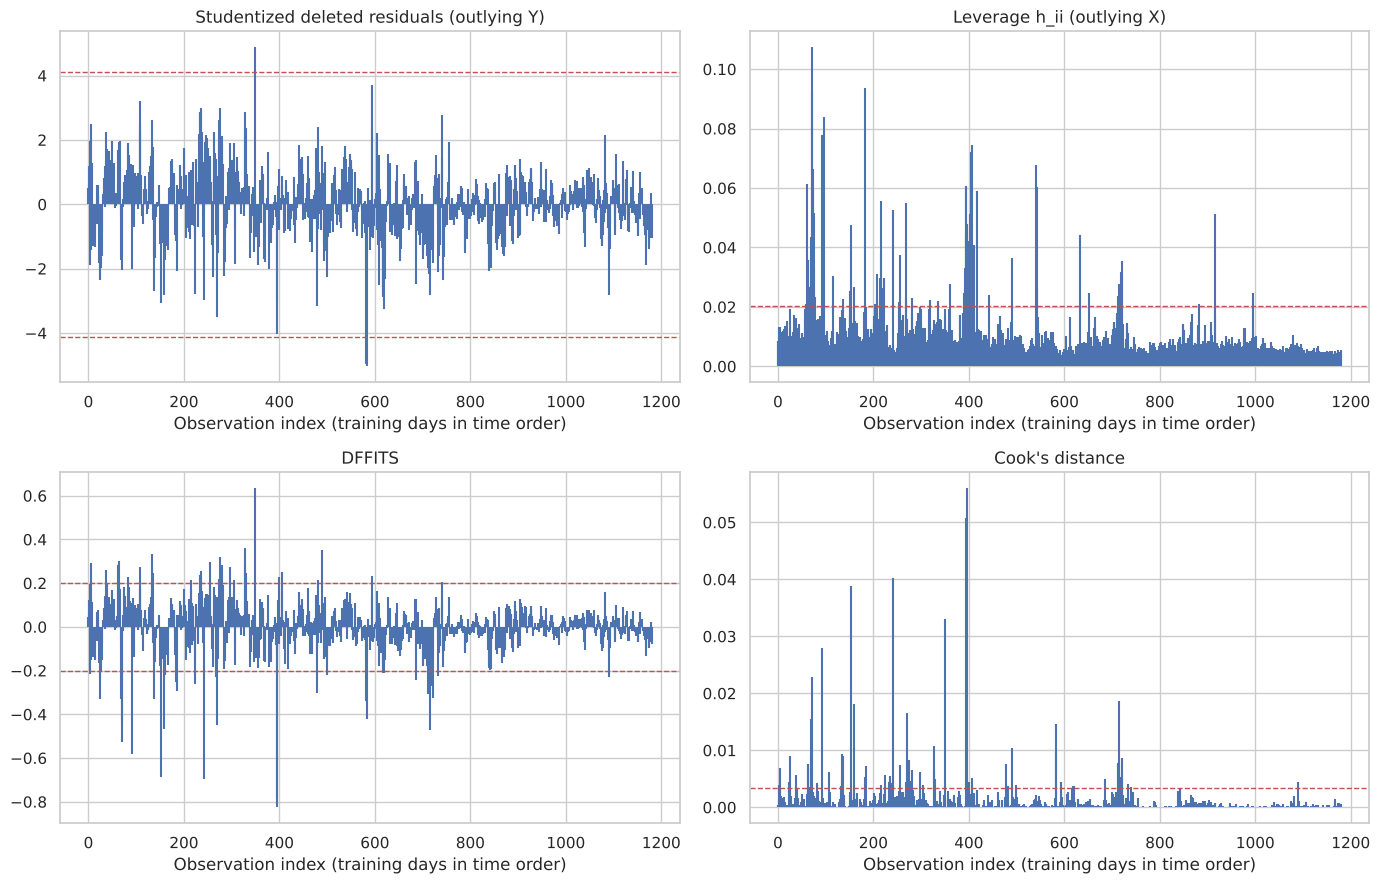

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
idx = np.arange(n)
axes[0, 0].stem(idx, measures["stud_deleted_resid"], markerfmt=" ", basefmt=" ")
for s in (1, -1): axes[0, 0].axhline(s * thr["t_bonferroni"], color="r", ls="--", lw=1)
axes[0, 0].set_title("Studentized deleted residuals (outlying Y)")
axes[0, 1].stem(idx, measures["leverage_hii"], markerfmt=" ", basefmt=" ")
axes[0, 1].axhline(thr["leverage"], color="r", ls="--", lw=1); axes[0, 1].set_title("Leverage h_ii (outlying X)")
axes[1, 0].stem(idx, measures["DFFITS"], markerfmt=" ", basefmt=" ")
for s in (1, -1): axes[1, 0].axhline(s * thr["DFFITS"], color="r", ls="--", lw=1)
axes[1, 0].set_title("DFFITS")
axes[1, 1].stem(idx, measures["cooks_D"], markerfmt=" ", basefmt=" ")
axes[1, 1].axhline(thr["Cook_4_over_n"], color="r", ls="--", lw=1); axes[1, 1].set_title("Cook's distance")
for ax in axes.ravel(): ax.set_xlabel("Observation index (training days in time order)")
fig.tight_layout(); fig.savefig(FIG / "13_influence_measures.png", dpi=150); plt.show()

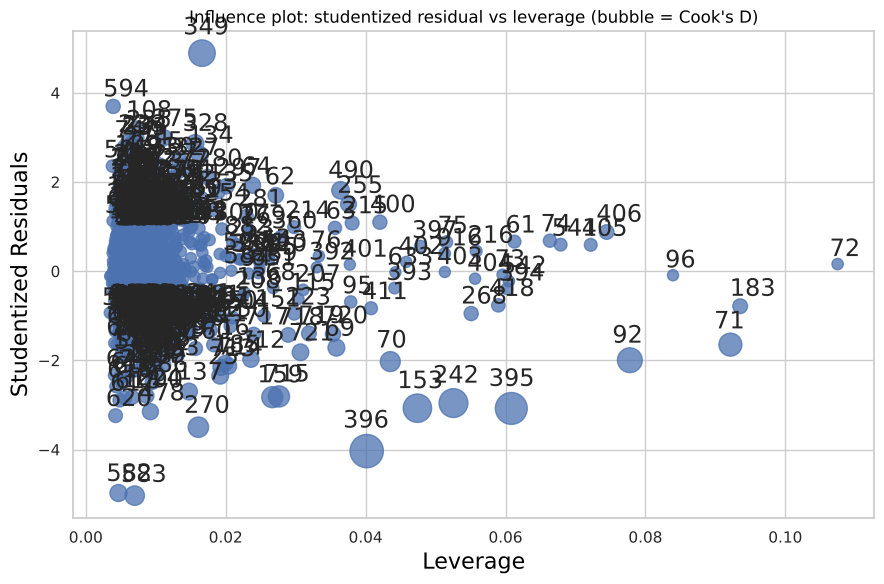

In [14]:
fig, ax = plt.subplots(figsize=(9, 6))
sm.graphics.influence_plot(log_ols, criterion="cooks", ax=ax, size=24, alpha=0.4)
ax.set_title("Influence plot: studentized residual vs leverage (bubble = Cook's D)")
fig.tight_layout(); fig.savefig(FIG / "14_influence_plot.png", dpi=150); plt.show()

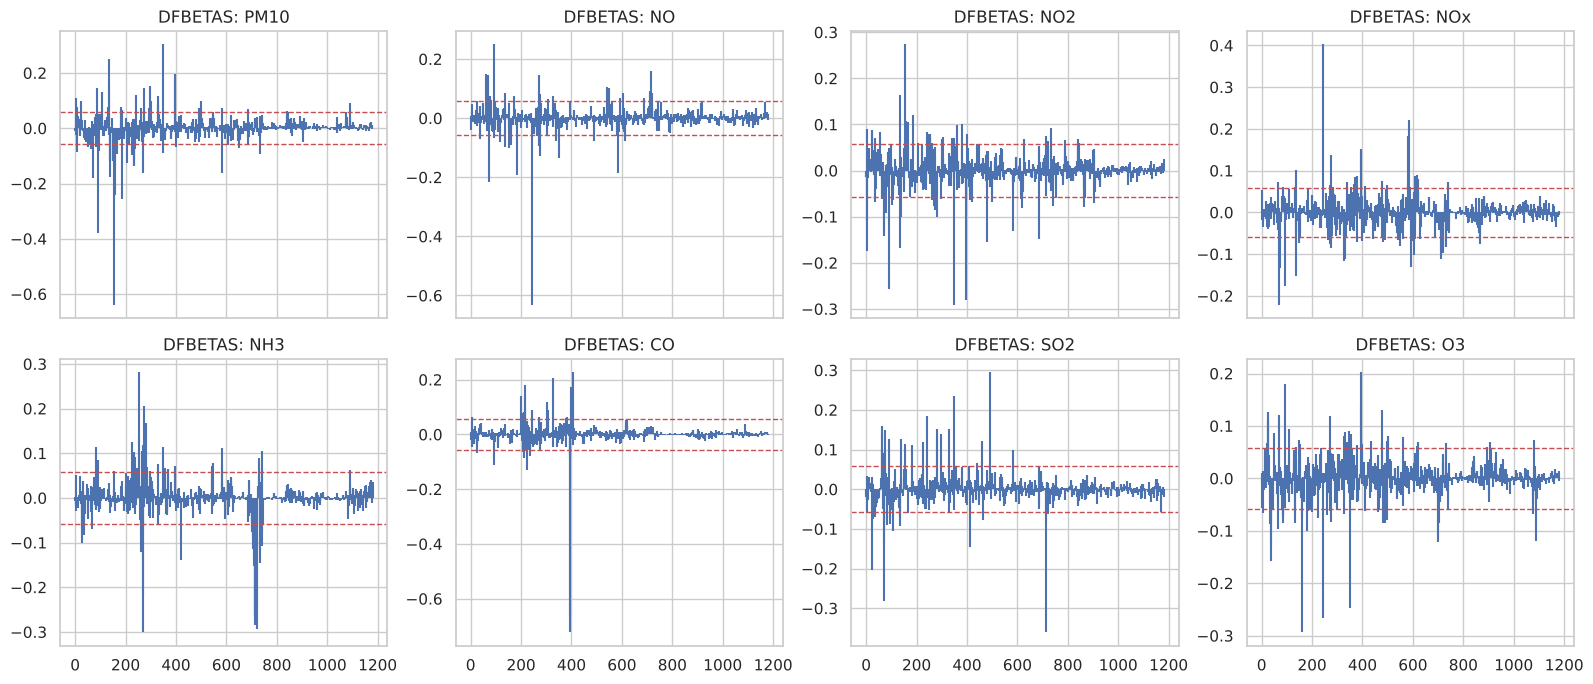

In [15]:
db_cols = [c for c in dfbetas.columns if "Season" not in c and c != "DFBETAS_Intercept"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharex=True)
for ax, c in zip(axes.ravel(), db_cols):
    ax.stem(idx, dfbetas[c], markerfmt=" ", basefmt=" ")
    for s in (1, -1): ax.axhline(s * thr["DFBETAS"], color="r", ls="--", lw=1)
    ax.set_title(c.replace("DFBETAS_", "DFBETAS: "))
fig.tight_layout(); fig.savefig(FIG / "15_dfbetas.png", dpi=150); plt.show()

## 10. Sensitivity check: refit without the influential days

Influential points are **not deleted automatically**. They are real pollution events. Refitting without them shows how much the conclusions depend on them.

In [16]:
influential = flags["Influential (Cook's D > 4/n)"].values
log_clean = smf.ols("np.log(PM25) ~ " + RHS, data=train[~influential]).fit()
sens = pd.DataFrame({
    "coef (all days)": log_ols.params, "p (all days)": log_ols.pvalues,
    "coef (without influential)": log_clean.params, "p (without influential)": log_clean.pvalues,
})
sens["% change"] = (sens["coef (without influential)"] / sens["coef (all days)"] - 1) * 100
sens.to_csv(TAB / "influence_sensitivity.csv")
print(f"Removed {influential.sum()} days | Adj R2: {log_ols.rsquared_adj:.3f} -> {log_clean.rsquared_adj:.3f}")
sens.round(4)

Removed 72 days | Adj R2: 0.609 -> 0.706


,coef (all days),p (all days),coef (without influential),p (without influential),% change
Intercept,2.7137,0.0000,2.6185,0.0000,-3.5104
"C(Season, Treatment('Winter'))[T.Monsoon]",-0.3629,0.0000,-0.3302,0.0000,-8.9944
"C(Season, Treatment('Winter'))[T.Post-monsoon]",-0.0422,0.1888,-0.0689,0.0108,63.4713
"C(Season, Treatment('Winter'))[T.Summer]",-0.0306,0.3100,-0.0110,0.6609,-64.0201
PM10,0.0042,0.0000,0.0044,0.0000,5.1213
NO,-0.0076,0.0000,-0.0082,0.0000,8.0884
NO2,0.0047,0.0000,0.0069,0.0000,45.6644
NOx,0.0080,0.0000,0.0087,0.0000,9.6647
NH3,0.0043,0.0000,0.0048,0.0000,12.0121
CO,-0.0283,0.0068,-0.0224,0.0194,-20.8329


## 11. Out-of-sample check of the remedied model

The log model predicts log(PM2.5). To compare with notebook 03 on the original scale, predictions are back-transformed with Duan's smearing factor, which corrects the bias of simply taking exp().

In [17]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
smear = np.mean(np.exp(log_ols.resid))
pred_log = np.exp(log_ols.predict(test)) * smear
pred_lin = ols.predict(test)
oos = pd.DataFrame({
    "RMSE_test": [np.sqrt(mean_squared_error(test.PM25, pred_lin)), np.sqrt(mean_squared_error(test.PM25, pred_log))],
    "MAE_test": [mean_absolute_error(test.PM25, pred_lin), mean_absolute_error(test.PM25, pred_log)],
    "R2_test": [r2_score(test.PM25, pred_lin), r2_score(test.PM25, pred_log)],
    "min prediction": [pred_lin.min(), pred_log.min()],
}, index=["MLR 2 (PM2.5)", "MLR 2 (log PM2.5)"])
oos.to_csv(TAB / "log_model_test_performance.csv")
print(f"Smearing factor = {smear:.4f}")
oos

Smearing factor = 1.0502


,RMSE_test,MAE_test,R2_test,min prediction
MLR 2 (PM2.5),8.5710,6.8621,0.5838,10.7032
MLR 2 (log PM2.5),8.0505,6.4767,0.6328,16.0952


## 12. Summary of assumption tests

In [18]:
final = compare.copy()
final["Assumption met? (before)"] = ""
final["Assumption met? (after)"] = ""
for i in final.index:
    for col, tgt in [("MLR 2 (PM2.5)", "Assumption met? (before)"), ("MLR 2 (log PM2.5)", "Assumption met? (after)")]:
        v = final.loc[i, col]
        if i.endswith(" p"):
            final.loc[i, tgt] = "Yes" if v >= 0.05 else "No"
        elif "Durbin" in i:
            final.loc[i, tgt] = "Yes" if 1.5 <= v <= 2.5 else "No"
final.to_csv(TAB / "assumption_tests.csv")
final

,MLR 2 (PM2.5),MLR 2 (log PM2.5),Assumption met? (before),Assumption met? (after)
Linearity: Rainbow p,0.0003,0.1045,No,Yes
Normality: residual skew,2.5915,-0.2013,,
Normality: Jarque-Bera p,0.0000,0.0000,No,No
Normality: Shapiro-Wilk p,0.0000,0.0000,No,No
Homoscedasticity: Breusch-Pagan p,0.0000,0.0000,No,No
Homoscedasticity: White p,0.0000,0.0000,No,No
Independence: Durbin-Watson,0.9991,0.9041,No,No
Independence: Ljung-Box (lag 7) p,0.0000,0.0000,No,No
Adjusted R²,0.5630,0.6091,,
